In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

Image dataset folder: /kaggle/input/datasets/alexanderuzhinskiy/pepper-disease-classification-dataset-doctorp/Pepper
Found 291 files belonging to 13 classes.
Using 233 files for training.
Found 291 files belonging to 13 classes.
Using 58 files for validation.
Classes: ['Aphid', 'Bacterial spot', 'Blossom end rot', 'Burn', 'Edema', 'Healthy', 'Leaf curl', 'Leaf miners', 'Mosaic virus', 'Nutrient deficiency', 'Powdery mildew', 'Spider mite', 'Thrips']
Number of classes: 13


2026-10-26 10:03:44.740763: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


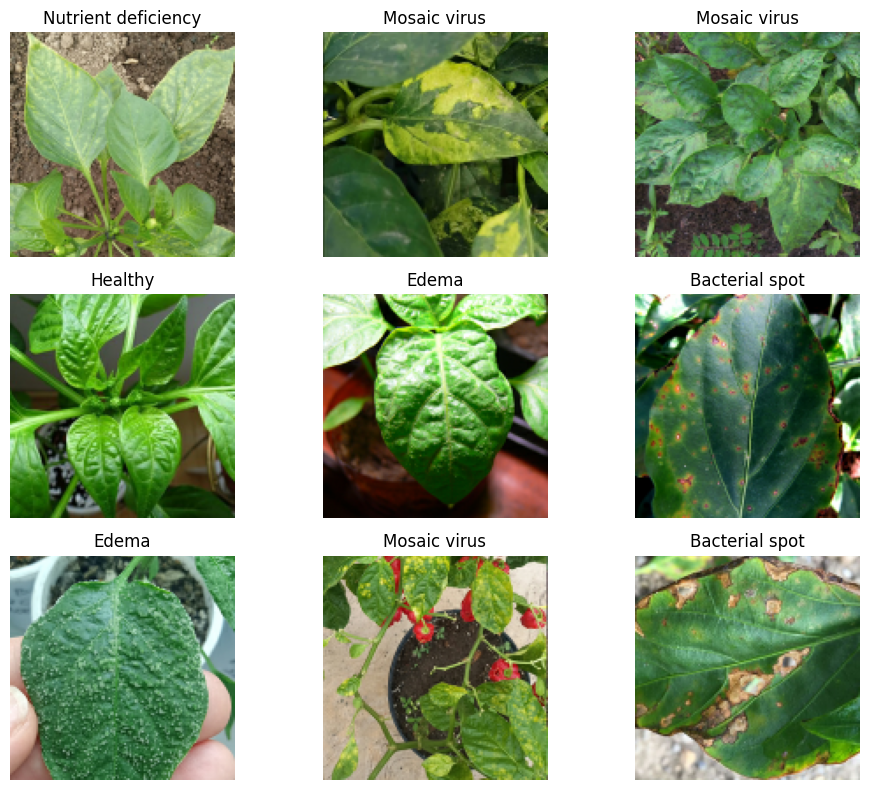

In [1]:
import os
from pathlib import Path
import tensorflow as tf
import matplotlib.pyplot as plt

DATA_PATH = Path(
    "/kaggle/input/datasets/alexanderuzhinskiy/pepper-disease-classification-dataset-doctorp"
)

# Find image folders
image_ext = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
class_folders = []

for root, dirs, files in os.walk(DATA_PATH):
    folder = Path(root)

    if any(
        (folder / d).is_dir()
        and any(
            f.is_file() and f.suffix.lower() in image_ext
            for f in (folder / d).iterdir()
        )
        for d in dirs
    ):
        class_folders.append(folder)

if not DATA_PATH.exists():
    print("Dataset path not found. Check Add Input in Kaggle.")
elif not class_folders:
    print("Class folders not found. Inspect the dataset folder structure.")
else:
    DATA_DIR = max(
        class_folders,
        key=lambda p: sum(
            1 for d in p.iterdir()
            if d.is_dir() and any(
                f.is_file() and f.suffix.lower() in image_ext
                for f in d.iterdir()
            )
        )
    )

    print("Image dataset folder:", DATA_DIR)

    train_ds = tf.keras.utils.image_dataset_from_directory(
        str(DATA_DIR),
        validation_split=0.2,
        subset="training",
        seed=42,
        image_size=(128, 128),
        batch_size=32,
        label_mode="int"
    )

    val_ds = tf.keras.utils.image_dataset_from_directory(
        str(DATA_DIR),
        validation_split=0.2,
        subset="validation",
        seed=42,
        image_size=(128, 128),
        batch_size=32,
        label_mode="int"
    )

    class_names = train_ds.class_names

    print("Classes:", class_names)
    print("Number of classes:", len(class_names))

    images, labels = next(iter(train_ds))

    plt.figure(figsize=(10, 8))
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [2]:
if "train_ds" in globals() and "val_ds" in globals():

    AUTOTUNE = tf.data.AUTOTUNE
    train_ds = train_ds.prefetch(AUTOTUNE)
    val_ds = val_ds.prefetch(AUTOTUNE)

    num_classes = len(class_names)

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(128, 128, 3)),
        tf.keras.layers.Rescaling(1.0 / 255),

        tf.keras.layers.Conv2D(32, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(64, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(128, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(num_classes, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    model.summary()

else:
    print("Run Cell 1 successfully first.")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 13)             │         1,677 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,437 (435.30 KB)

 Trainable params: 111,437 (435.30 KB)

 Non-trainable params: 0 (0.00 B)

In [3]:
if "model" in globals() and "train_ds" in globals():

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=10
    )

else:
    print("Run Cells 1 and 2 successfully first.")

Epoch 1/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.0858 - loss: 2.5179 - val_accuracy: 0.1034 - val_loss: 2.4165
Epoch 2/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 493ms/step - accuracy: 0.1288 - loss: 2.4252 - val_accuracy: 0.1724 - val_loss: 2.3385
Epoch 3/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 485ms/step - accuracy: 0.1459 - loss: 2.3983 - val_accuracy: 0.1724 - val_loss: 2.3329
Epoch 4/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 5s 496ms/step - accuracy: 0.1245 - loss: 2.4019 - val_accuracy: 0.1724 - val_loss: 2.3341
Epoch 5/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 498ms/step - accuracy: 0.1459 - loss: 2.3712 - val_accuracy: 0.1724 - val_loss: 2.3177
Epoch 6/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 5s 535ms/step - accuracy: 0.1845 - loss: 2.3424 - val_accuracy: 0.1724 - val_loss: 2.3246
Epoch 7/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 496ms/step - accuracy: 0.1888 - loss: 2.3739 - val_accuracy: 0.2414 - val_loss: 2.3252
Epoch 8/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 5s 495ms/step - accuracy: 0.1502 - loss: 2.3573 - val_accuracy: 0.2069 - val_loss: 2

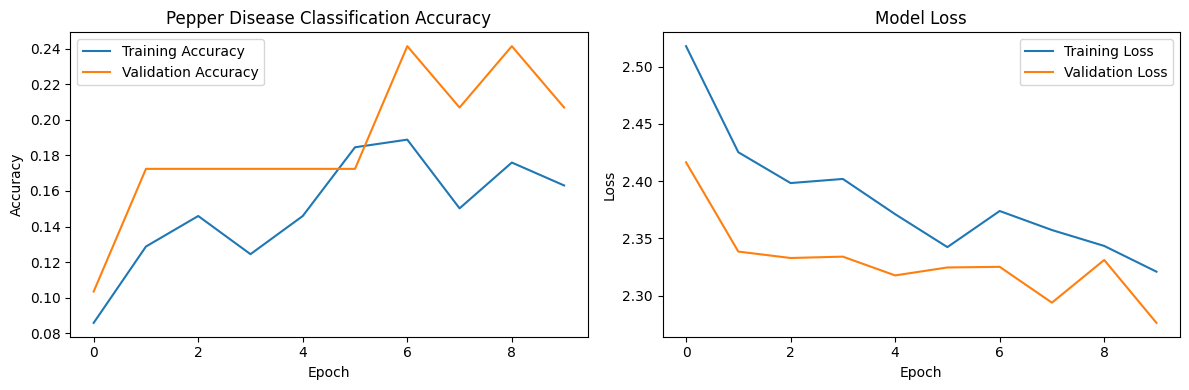

In [4]:
if "history" in globals():

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history.history["accuracy"], label="Training Accuracy")
    plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
    plt.title("Pepper Disease Classification Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history["loss"], label="Training Loss")
    plt.plot(history.history["val_loss"], label="Validation Loss")
    plt.title("Model Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()

else:
    print("Train the model first.")

In [5]:
if "model" in globals() and "val_ds" in globals():

    loss, accuracy = model.evaluate(val_ds)

    print(f"Validation Loss: {loss:.4f}")
    print(f"Validation Accuracy: {accuracy * 100:.2f}%")

    model.save("/kaggle/working/pepper_disease_cnn.keras")
    print("Model saved successfully.")

else:
    print("Train the model before evaluating it.")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.2069 - loss: 2.2762
Validation Loss: 2.2762
Validation Accuracy: 20.69%
Model saved successfully.


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step
PEPPER DISEASE CLASSIFICATION REPORT
                     precision    recall  f1-score   support

              Aphid       0.00      0.00      0.00         6
     Bacterial spot       0.00      0.00      0.00         5
    Blossom end rot       0.00      0.00      0.00         3
               Burn       0.00      0.00      0.00         1
              Edema       0.00      0.00      0.00        10
            Healthy       0.18      1.00      0.31        10
          Leaf curl       0.00      0.00      0.00         8
        Leaf miners       0.00      0.00      0.00         2
       Mosaic virus       0.00      0.00      0.00         1
Nutrient deficiency       0.00      0.00      0.00         6
     Powdery mildew       0.00      0.00      0.00         5
        Spider mite       0.00      0.00      0.00         0
             Thrips       0.00      0.00      0.00         1

           accuracy                           0.17        58
       

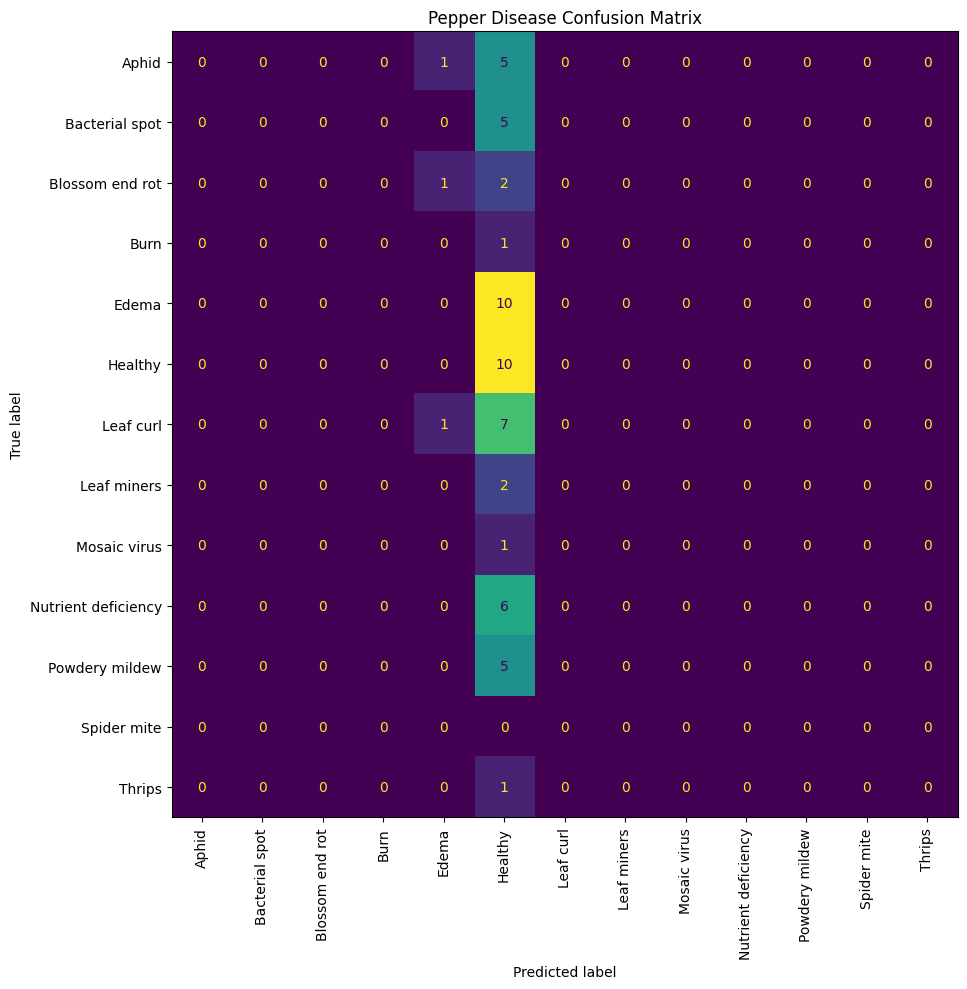

In [6]:
import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

if "model" in globals() and "val_ds" in globals():

    # Actual labels
    y_true = np.concatenate([
        labels.numpy() for images, labels in val_ds
    ])

    # Predicted labels
    y_prob = model.predict(val_ds, verbose=1)
    y_pred = np.argmax(y_prob, axis=1)

    # Classification report
    print("PEPPER DISEASE CLASSIFICATION REPORT")
    print(classification_report(
        y_true,
        y_pred,
        labels=range(len(class_names)),
        target_names=class_names,
        zero_division=0
    ))

    # Confusion matrix
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=range(len(class_names))
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    fig, ax = plt.subplots(figsize=(10, 10))
    display.plot(
        ax=ax,
        xticks_rotation="vertical",
        colorbar=False
    )
    plt.title("Pepper Disease Confusion Matrix")
    plt.tight_layout()
    plt.show()

else:
    print("Run Cells 1–5 successfully before this cell.")

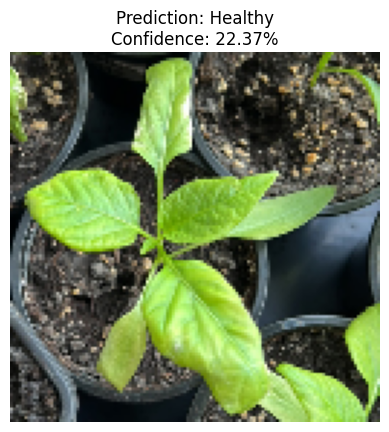

Image: np_b_i1.jpg
Predicted class: Healthy
Prediction confidence: 22.37%


In [7]:
import random
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

if "model" in globals() and "class_names" in globals():

    # Find images in the dataset
    image_ext = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

    image_files = [
        p for p in DATA_DIR.rglob("*")
        if p.is_file() and p.suffix.lower() in image_ext
    ]

    if image_files:
        # Select a sample image
        image_path = random.choice(image_files)

        # Load and prepare the image
        img = tf.keras.utils.load_img(
            image_path,
            target_size=(128, 128)
        )
        img_array = tf.keras.utils.img_to_array(img)
        img_array = np.expand_dims(img_array, axis=0)

        # Predict the class
        probabilities = model.predict(img_array, verbose=0)[0]
        predicted_index = int(np.argmax(probabilities))
        predicted_class = class_names[predicted_index]
        confidence = probabilities[predicted_index] * 100

        # Display result
        plt.imshow(img)
        plt.axis("off")
        plt.title(
            f"Prediction: {predicted_class}\n"
            f"Confidence: {confidence:.2f}%"
        )
        plt.show()

        print("Image:", image_path.name)
        print("Predicted class:", predicted_class)
        print(f"Prediction confidence: {confidence:.2f}%")

    else:
        print("No images found in DATA_DIR.")

else:
    print("Train the model and run Cell 1 first.")

Training history saved.


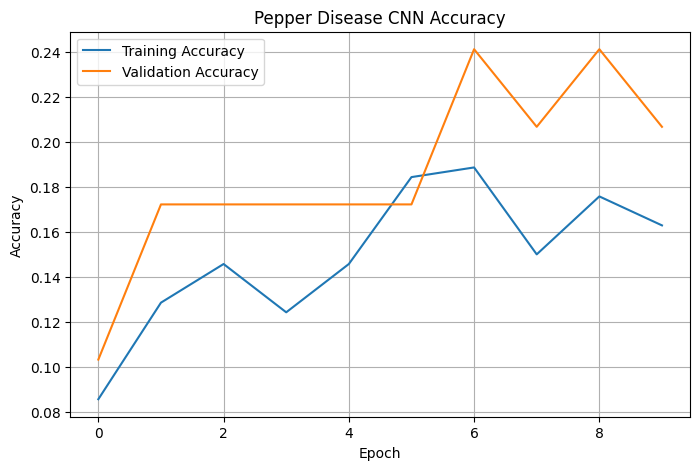

Accuracy graph saved.


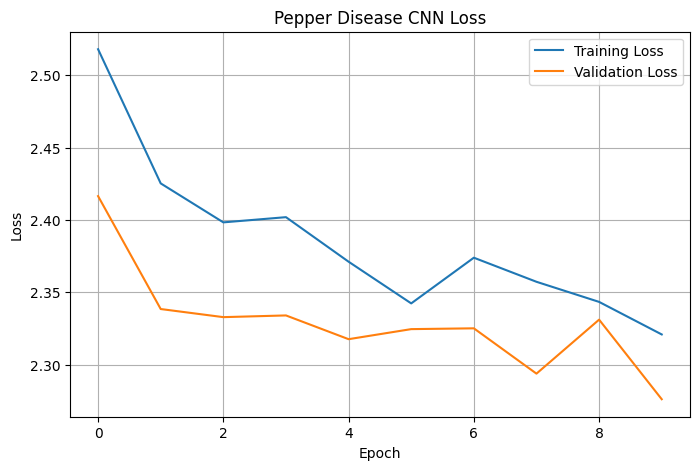

Loss graph saved.

Files in output folder:
['pepper_accuracy_graph.png', 'pepper_loss_graph.png', '.virtual_documents', 'pepper_disease_cnn.keras', 'pepper_training_history.csv']


In [8]:
import os
import pandas as pd
import matplotlib.pyplot as plt

output_dir = "/kaggle/working"
os.makedirs(output_dir, exist_ok=True)

if "history" in globals():

    # Save training history
    history_df = pd.DataFrame(history.history)
    history_df.index.name = "Epoch"
    history_df.to_csv(
        os.path.join(output_dir, "pepper_training_history.csv")
    )

    print("Training history saved.")

    # Save accuracy graph
    plt.figure(figsize=(8, 5))
    plt.plot(history.history["accuracy"], label="Training Accuracy")
    plt.plot(
        history.history["val_accuracy"],
        label="Validation Accuracy"
    )
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title("Pepper Disease CNN Accuracy")
    plt.legend()
    plt.grid(True)
    plt.savefig(
        os.path.join(output_dir, "pepper_accuracy_graph.png"),
        bbox_inches="tight"
    )
    plt.show()

    print("Accuracy graph saved.")

    # Save loss graph
    plt.figure(figsize=(8, 5))
    plt.plot(history.history["loss"], label="Training Loss")
    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Pepper Disease CNN Loss")
    plt.legend()
    plt.grid(True)
    plt.savefig(
        os.path.join(output_dir, "pepper_loss_graph.png"),
        bbox_inches="tight"
    )
    plt.show()

    print("Loss graph saved.")
    print("\nFiles in output folder:")
    print(os.listdir(output_dir))

else:
    print("Training history not found. Run Cell 3 first.")

In [10]:
import pandas as pd
from IPython.display import display

if "history" in globals():

    history_df = pd.DataFrame(history.history)

    best_epoch = history_df["val_accuracy"].idxmax()
    best_val_accuracy = history_df.loc[best_epoch, "val_accuracy"]
    final_train_accuracy = history_df["accuracy"].iloc[-1]
    final_val_accuracy = history_df["val_accuracy"].iloc[-1]
    final_train_loss = history_df["loss"].iloc[-1]
    final_val_loss = history_df["val_loss"].iloc[-1]

    summary = pd.DataFrame({
        "Metric": [
            "Total Epochs",
            "Final Training Accuracy",
            "Final Validation Accuracy",
            "Best Validation Accuracy",
            "Final Training Loss",
            "Final Validation Loss",
            "Best Epoch"
        ],
        "Value": [
            len(history_df),
            f"{final_train_accuracy * 100:.2f}%",
            f"{final_val_accuracy * 100:.2f}%",
            f"{best_val_accuracy * 100:.2f}%",
            f"{final_train_loss:.4f}",
            f"{final_val_loss:.4f}",
            int(best_epoch + 1)
        ]
    })

    print("PEPPER DISEASE CNN — FINAL SUMMARY")
    display(summary)

    summary.to_csv(
        "/kaggle/working/pepper_final_model_summary.csv",
        index=False
    )
    print("Summary saved to /kaggle/working/pepper_final_model_summary.csv")

else:
    print("Training history not found. Run Cell 3 first.")

PEPPER DISEASE CNN — FINAL SUMMARY


,Metric,Value
0,Total Epochs,10
1,Final Training Accuracy,16.31%
2,Final Validation Accuracy,20.69%
3,Best Validation Accuracy,24.14%
4,Final Training Loss,2.3210
5,Final Validation Loss,2.2762
6,Best Epoch,7


Summary saved to /kaggle/working/pepper_final_model_summary.csv


In [11]:
import tensorflow as tf
import matplotlib.pyplot as plt

if "train_ds" in globals() and "val_ds" in globals():

    # Load pretrained MobileNetV2
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=(128, 128, 3),
        include_top=False,
        weights="imagenet"
    )

    # Freeze pretrained layers
    base_model.trainable = False

    # Build transfer-learning model
    inputs = tf.keras.layers.Input(shape=(128, 128, 3))

    x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
    x = base_model(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(
        len(class_names),
        activation="softmax"
    )(x)

    transfer_model = tf.keras.Model(inputs, outputs)

    transfer_model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    transfer_model.summary()

    # Train the model
    transfer_history = transfer_model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=10
    )

else:
    print("Run Cell 1 successfully before training MobileNetV2.")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 13)             │        16,653 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,274,637 (8.68 MB)

 Trainable params: 16,653 (65.05 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 484ms/step - accuracy: 0.0515 - loss: 3.2150 - val_accuracy: 0.1379 - val_loss: 2.5168
Epoch 2/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 276ms/step - accuracy: 0.2489 - loss: 2.5047 - val_accuracy: 0.2586 - val_loss: 2.1543
Epoch 3/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 254ms/step - accuracy: 0.3820 - loss: 2.0041 - val_accuracy: 0.2931 - val_loss: 1.9789
Epoch 4/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 263ms/step - accuracy: 0.5150 - loss: 1.5641 - val_accuracy: 0.3448 - val_loss: 1.8124
Epoch 5/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 258ms/step - accuracy: 0.5622 - loss: 1.3769 - val_accuracy: 0.3793 - val_loss: 1.7205
Epoch 6/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 263ms/step - accuracy: 0.6910 - loss: 1.0684 - val_accuracy: 0.3276 - val_loss: 1.6261
Epoch 7/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 282ms/step - accuracy: 0.7339 - loss: 0.9478 - val_accuracy: 0.3621 - val_loss: 1.5672
Epoch 8/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 262ms/step - accuracy: 0.7296 - loss: 0.8626 - val_accuracy: 0.4310 - val_loss:

In [12]:
if "transfer_model" in globals():

    loss, accuracy = transfer_model.evaluate(val_ds, verbose=1)

    print(f"MobileNetV2 Validation Accuracy: {accuracy * 100:.2f}%")
    print(f"Validation Loss: {loss:.4f}")

    transfer_model.save(
        "/kaggle/working/pepper_mobilenetv2.keras"
    )

    print("MobileNetV2 model saved successfully.")

else:
    print("Run Cell 10 successfully first.")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 0.4310 - loss: 1.4917
MobileNetV2 Validation Accuracy: 43.10%
Validation Loss: 1.4917
MobileNetV2 model saved successfully.


MODEL COMPARISON


,Model,Best Validation Accuracy (%),Best Validation Loss
0,Basic CNN,24.14,2.2762
1,MobileNetV2,43.10,1.4915


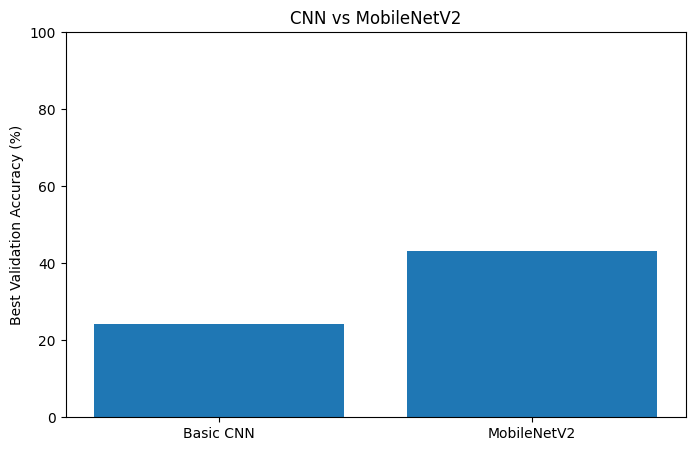

Comparison saved to /kaggle/working/pepper_model_comparison.csv


In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

results = []

# Basic CNN results
if "history" in globals():
    results.append({
        "Model": "Basic CNN",
        "Best Validation Accuracy (%)":
            max(history.history["val_accuracy"]) * 100,
        "Best Validation Loss":
            min(history.history["val_loss"])
    })

# MobileNetV2 results
if "transfer_history" in globals():
    results.append({
        "Model": "MobileNetV2",
        "Best Validation Accuracy (%)":
            max(transfer_history.history["val_accuracy"]) * 100,
        "Best Validation Loss":
            min(transfer_history.history["val_loss"])
    })

if results:
    comparison_df = pd.DataFrame(results)

    comparison_df["Best Validation Accuracy (%)"] = (
        comparison_df["Best Validation Accuracy (%)"].round(2)
    )
    comparison_df["Best Validation Loss"] = (
        comparison_df["Best Validation Loss"].round(4)
    )

    print("MODEL COMPARISON")
    display(comparison_df)

    comparison_df.to_csv(
        "/kaggle/working/pepper_model_comparison.csv",
        index=False
    )

    plt.figure(figsize=(8, 5))
    plt.bar(
        comparison_df["Model"],
        comparison_df["Best Validation Accuracy (%)"]
    )
    plt.ylabel("Best Validation Accuracy (%)")
    plt.title("CNN vs MobileNetV2")
    plt.ylim(0, 100)
    plt.show()

    print("Comparison saved to /kaggle/working/pepper_model_comparison.csv")

else:
    print("Run the training cells for at least one model first.")

Selected model: MobileNetV2


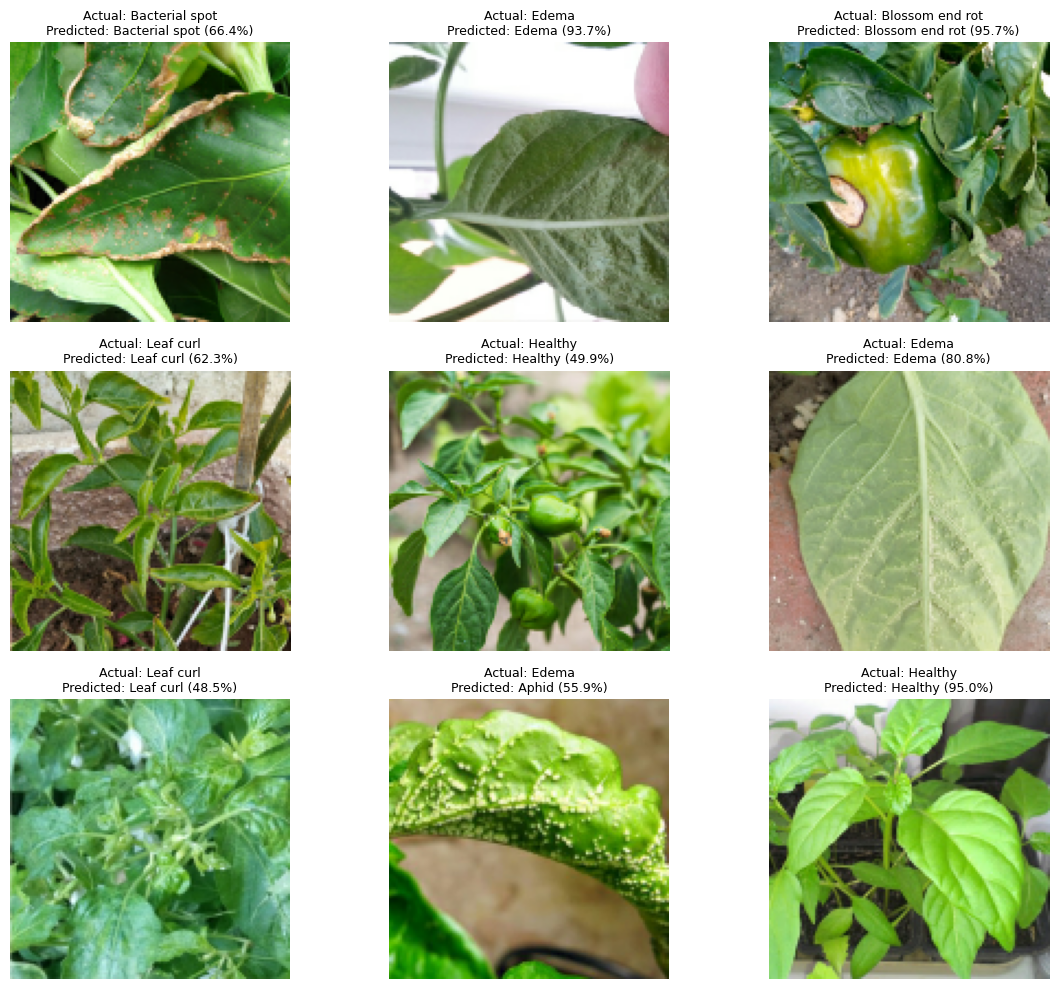

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Select the model with the best validation accuracy
trained_models = []

if "model" in globals() and "history" in globals():
    trained_models.append((
        max(history.history["val_accuracy"]),
        "Basic CNN",
        model
    ))

if "transfer_model" in globals() and "transfer_history" in globals():
    trained_models.append((
        max(transfer_history.history["val_accuracy"]),
        "MobileNetV2",
        transfer_model
    ))

if trained_models:
    _, best_model_name, best_model = max(
        trained_models, key=lambda item: item[0]
    )

    print("Selected model:", best_model_name)

    # Get one batch of validation images
    images, labels = next(iter(val_ds))
    probabilities = best_model.predict(images, verbose=0)
    predictions = np.argmax(probabilities, axis=1)

    plt.figure(figsize=(12, 10))

    for i in range(min(9, len(images))):
        actual = class_names[int(labels[i])]
        predicted = class_names[int(predictions[i])]
        confidence = probabilities[i][predictions[i]] * 100

        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(
            f"Actual: {actual}\n"
            f"Predicted: {predicted} ({confidence:.1f}%)",
            fontsize=9
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()

else:
    print("Train the CNN or MobileNetV2 model first.")

In [15]:
import os
import pandas as pd
from IPython.display import display

report_rows = []

# Dataset details
if "class_names" in globals():
    report_rows.append({
        "Item": "Number of classes",
        "Result": len(class_names)
    })

if "train_ds" in globals():
    report_rows.append({
        "Item": "Training batches",
        "Result": len(train_ds)
    })

if "val_ds" in globals():
    report_rows.append({
        "Item": "Validation batches",
        "Result": len(val_ds)
    })

# Basic CNN metrics
if "history" in globals():
    report_rows.extend([
        {
            "Item": "Basic CNN best validation accuracy",
            "Result": f"{max(history.history['val_accuracy']) * 100:.2f}%"
        },
        {
            "Item": "Basic CNN best validation loss",
            "Result": f"{min(history.history['val_loss']):.4f}"
        }
    ])

# MobileNetV2 metrics
if "transfer_history" in globals():
    report_rows.extend([
        {
            "Item": "MobileNetV2 best validation accuracy",
            "Result": f"{max(transfer_history.history['val_accuracy']) * 100:.2f}%"
        },
        {
            "Item": "MobileNetV2 best validation loss",
            "Result": f"{min(transfer_history.history['val_loss']):.4f}"
        }
    ])

if report_rows:
    final_report = pd.DataFrame(report_rows)

    print("PEPPER DISEASE CLASSIFICATION — FINAL REPORT")
    display(final_report)

    report_path = "/kaggle/working/pepper_final_project_report.csv"
    final_report.to_csv(report_path, index=False)

    print("\nReport saved to:", report_path)
else:
    print("No results found. Run the dataset and model training cells first.")

PEPPER DISEASE CLASSIFICATION — FINAL REPORT


,Item,Result
0,Number of classes,13
1,Training batches,8
2,Validation batches,2
3,Basic CNN best validation accuracy,24.14%
4,Basic CNN best validation loss,2.2762
5,MobileNetV2 best validation accuracy,43.10%
6,MobileNetV2 best validation loss,1.4915



Report saved to: /kaggle/working/pepper_final_project_report.csv


In [ ]:
import tensorflow as tf

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

print("Data augmentation module created successfully!")